In [1]:
import pandas as pd
import numpy as np

path = "AdvanceData/data"
results = pd.read_csv(f"{path}/results.csv")
races = pd.read_csv(f"{path}/races.csv")[["raceId", "year", "round"]]
constructors = pd.read_csv(f"{path}/constructors.csv")[["constructorId", "name"]]

# same team under different names (see the pivot in notebook 01)
lineage = {
    "Force India": "Aston Martin lineage", "Racing Point": "Aston Martin lineage", "Aston Martin": "Aston Martin lineage",
    "Toro Rosso": "AlphaTauri lineage", "AlphaTauri": "AlphaTauri lineage", "RB F1 Team": "AlphaTauri lineage",
    "Lotus F1": "Renault lineage", "Renault": "Renault lineage", "Alpine F1 Team": "Renault lineage",
    "Sauber": "Sauber lineage", "Alfa Romeo": "Sauber lineage",
    "Marussia": "Marussia lineage", "Manor Marussia": "Marussia lineage",
}

df = (results[["raceId", "driverId", "constructorId", "grid", "positionOrder", "points"]]
      .merge(races, on="raceId")
      .merge(constructors, on="constructorId"))
df["team"] = df["name"].map(lineage).fillna(df["name"])
df["win"] = (df["positionOrder"] == 1).astype(int)    # target: 1 if the driver won the race
df["grid"] = df["grid"].replace(0, 20)                # grid 0 = pit-lane start
df = df.sort_values(["year", "round"]).reset_index(drop=True)
df.shape

(26759, 11)

In [2]:
# driver features: only races BEFORE the current one
df["driver_wins_before"] = df.groupby("driverId")["win"].cumsum() - df["win"]
df["driver_team_wins_before"] = df.groupby(["driverId", "team"])["win"].cumsum() - df["win"]
df["driver_races_before"] = df.groupby("driverId").cumcount()
df["driver_form3"] = (df.groupby("driverId")["points"]
                        .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))

# car feature: the team's points per race over its previous 3 races
team_race = (df.groupby(["team", "year", "round", "raceId"], as_index=False)["points"].sum()
               .sort_values(["year", "round"]))
team_race["team_form3"] = (team_race.groupby("team")["points"]
                             .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))
df = df.merge(team_race[["team", "raceId", "team_form3"]], on=["team", "raceId"], how="left")

features = ["grid", "team_form3", "driver_form3",
            "driver_wins_before", "driver_team_wins_before", "driver_races_before"]
df[features] = df[features].fillna(0)    # first race of a driver/team: no history yet

In [3]:
data = df[df["year"].between(2014, 2024)].copy()
pre = data[data["year"] <= 2020]      # before the cap
post = data[data["year"] >= 2021]     # after the cap

print(pre.shape, post.shape)
print(data.groupby("raceId")["win"].sum().value_counts())    # should show only 1
print(data[features].isna().sum().sum())                     # should be 0

first_winner = data.loc[data["win"] == 1, "driverId"].iloc[0]
data.loc[data["driverId"] == first_winner,
         ["year", "round", "grid", "positionOrder", "win", "driver_wins_before"]].head(8)

(2827, 16) (1799, 16)
win
1    228
Name: count, dtype: int64
0


,year,round,grid,positionOrder,win,driver_wins_before
22133,2014,1,3,1,1,3
22156,2014,2,3,2,0,4
22178,2014,3,1,2,0,4
22200,2014,4,4,2,0,4
22222,2014,5,2,2,0,4
22243,2014,6,1,1,1,4
22266,2014,7,1,2,0,5
22287,2014,8,3,1,1,5


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

def fit_model(train_df):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return m.fit(train_df[features], train_df["win"])

def score(m, d, base_rate, year, period):
    p = m.predict_proba(d[features])[:, 1]
    top = d.assign(p=p).sort_values("p", ascending=False).groupby("raceId").head(1)
    return {"year": year, "period": period,
            "AUC": roc_auc_score(d["win"], p),
            "log_loss": log_loss(d["win"], p),
            "log_loss_baseline": log_loss(d["win"], np.full(len(d), base_rate)),
            "top_pick_hit": top["win"].mean(),
            "pole_hit": d.loc[d["grid"] == 1, "win"].mean()}

rows = []
# (a) pre-cap reference: leave one season out
for y in range(2014, 2021):
    train_y = pre[pre["year"] != y]
    rows.append(score(fit_model(train_y), pre[pre["year"] == y],
                      train_y["win"].mean(), y, "pre-cap (held-out season)"))
# (b) post-cap: model trained on all pre-cap seasons
m_pre = fit_model(pre)
for y in range(2021, 2025):
    rows.append(score(m_pre, post[post["year"] == y], pre["win"].mean(), y, "post-cap"))

res = pd.DataFrame(rows).round(3)
res

,year,period,AUC,log_loss,log_loss_baseline,top_pick_hit,pole_hit
0,2014,pre-cap (held-out season),0.942,0.112,0.189,0.526,0.474
1,2015,pre-cap (held-out season),0.974,0.090,0.199,0.579,0.632
2,2016,pre-cap (held-out season),0.974,0.083,0.185,0.667,0.619
3,2017,pre-cap (held-out season),0.951,0.108,0.199,0.550,0.550
4,2018,pre-cap (held-out season),0.941,0.113,0.199,0.524,0.476
5,2019,pre-cap (held-out season),0.958,0.102,0.199,0.476,0.381
6,2020,pre-cap (held-out season),0.942,0.103,0.199,0.647,0.588
7,2021,post-cap,0.934,0.125,0.199,0.455,0.500
8,2022,post-cap,0.924,0.127,0.199,0.409,0.455
9,2023,post-cap,0.981,0.075,0.199,0.727,0.636


                             AUC        log_loss        top_pick_hit         \
                            mean    std     mean    std         mean    std   
period                                                                        
post-cap                   0.942  0.026    0.112  0.025        0.523  0.141   
pre-cap (held-out season)  0.955  0.015    0.102  0.011        0.567  0.069   

                          pole_hit         
                              mean    std  
period                                     
post-cap                     0.512  0.085  
pre-cap (held-out season)    0.531  0.092  


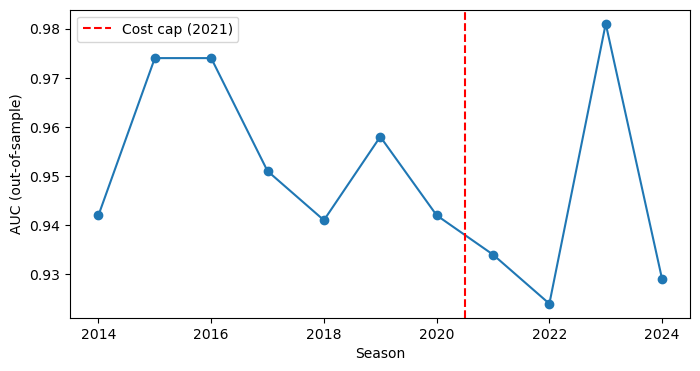

grid                      -2.86
driver_races_before       -0.31
driver_team_wins_before    0.11
team_form3                 0.20
driver_wins_before         0.30
driver_form3               0.41
dtype: float64

In [5]:
import matplotlib.pyplot as plt

print(res.groupby("period")[["AUC", "log_loss", "top_pick_hit", "pole_hit"]]
         .agg(["mean", "std"]).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(res["year"], res["AUC"], marker="o")
ax.axvline(2020.5, color="red", linestyle="--", label="Cost cap (2021)")
ax.set_xlabel("Season"); ax.set_ylabel("AUC (out-of-sample)"); ax.legend()
plt.show()

pd.Series(m_pre[-1].coef_[0], index=features).sort_values().round(2)

In [6]:
rows = []
for y in range(2017, 2025):
    train_y = data[data["year"] < y]                  # only earlier seasons
    test_y = data[data["year"] == y]
    period = "pre-cap" if y <= 2020 else "post-cap"
    rows.append(score(fit_model(train_y), test_y, train_y["win"].mean(), y, period))

res_wf = pd.DataFrame(rows).round(3)
print(res_wf)
print(res_wf.groupby("period")[["AUC", "log_loss", "top_pick_hit", "pole_hit"]].agg(["mean", "std"]).round(3))

   year    period    AUC  log_loss  log_loss_baseline  top_pick_hit  pole_hit
0  2017   pre-cap  0.951     0.109              0.199         0.450     0.550
1  2018   pre-cap  0.941     0.113              0.199         0.524     0.476
2  2019   pre-cap  0.959     0.102              0.199         0.476     0.381
3  2020   pre-cap  0.942     0.103              0.199         0.647     0.588
4  2021  post-cap  0.934     0.125              0.199         0.455     0.500
5  2022  post-cap  0.926     0.125              0.199         0.364     0.455
6  2023  post-cap  0.985     0.070              0.199         0.818     0.636
7  2024  post-cap  0.933     0.119              0.199         0.500     0.458
            AUC        log_loss        top_pick_hit        pole_hit       
           mean    std     mean    std         mean    std     mean    std
period                                                                    
post-cap  0.944  0.027    0.110  0.027        0.534  0.197    0.512  0.08

In [7]:
data[data["year"] == 2023].groupby("team")["win"].sum().sort_values().tail(3)

team
Sauber lineage     0
Ferrari            1
Red Bull          21
Name: win, dtype: int64

In [8]:
from sklearn.linear_model import LogisticRegression

d = data.copy()
post = (d["year"] >= 2021).astype(int)

Z = (d[features] - d[features].mean()) / d[features].std()     # standardised
for f in ["grid", "team_form3", "driver_form3"]:
    Z[f + "_x_post"] = Z[f] * post                              # does the weight of f change after the cap?
Z["post_cap"] = post
y = d["win"]

def fit_coefs(Zs, ys):
    m = LogisticRegression(max_iter=2000, C=1e6)               # almost no regularisation, like a plain logit
    m.fit(Zs, ys)
    return pd.Series(m.coef_[0], index=Zs.columns)

base = fit_coefs(Z, y)

# bootstrap by race: resample whole races, so drivers of the same race stay together
rng = np.random.default_rng(0)
race_ids = d["raceId"].unique()
groups = d.groupby("raceId").indices
boot = []
for _ in range(200):
    pick = rng.choice(race_ids, size=len(race_ids), replace=True)
    idx = np.concatenate([groups[r] for r in pick])
    boot.append(fit_coefs(Z.iloc[idx], y.iloc[idx]))
boot = pd.DataFrame(boot)

out = pd.DataFrame({"coef": base,
                    "ci_low": boot.quantile(0.025),
                    "ci_high": boot.quantile(0.975)}).round(2)
out

,coef,ci_low,ci_high
grid,-3.49,-5.15,-2.36
team_form3,0.05,-0.41,0.53
driver_form3,0.54,0.16,0.96
driver_wins_before,0.15,-0.27,0.54
driver_team_wins_before,0.20,-0.08,0.58
driver_races_before,-0.36,-0.66,-0.10
grid_x_post,1.34,-0.80,3.39
team_form3_x_post,0.36,-0.33,0.95
driver_form3_x_post,0.17,-0.49,0.79
post_cap,1.12,-1.28,3.38


In [9]:
def interaction_table(d, n_boot=200, seed=0):
    d = d.reset_index(drop=True)
    post = (d["year"] >= 2021).astype(int)
    Z = (d[features] - d[features].mean()) / d[features].std()
    for f in ["grid", "team_form3", "driver_form3"]:
        Z[f + "_x_post"] = Z[f] * post
    Z["post_cap"] = post
    y = d["win"]
    base = fit_coefs(Z, y)
    rng = np.random.default_rng(seed)
    race_ids = d["raceId"].unique()
    groups = d.groupby("raceId").indices
    boot = []
    for _ in range(n_boot):
        pick = rng.choice(race_ids, size=len(race_ids), replace=True)
        idx = np.concatenate([groups[r] for r in pick])
        boot.append(fit_coefs(Z.iloc[idx], y.iloc[idx]))
    boot = pd.DataFrame(boot)
    return pd.DataFrame({"coef": base, "ci_low": boot.quantile(0.025),
                         "ci_high": boot.quantile(0.975)}).round(2)

rows = ["grid_x_post", "team_form3_x_post", "driver_form3_x_post", "post_cap"]
print("Without 2022")
display(interaction_table(data[data["year"] != 2022]).loc[rows])
print("Only 2021 as post-cap (the year with the cap but not the new cars)")
display(interaction_table(data[data["year"] <= 2021]).loc[rows])

Without 2022


,coef,ci_low,ci_high
grid_x_post,1.23,-1.46,3.45
team_form3_x_post,0.23,-0.59,1.01
driver_form3_x_post,0.25,-0.46,1.09
post_cap,1.02,-2.21,3.67


Only 2021 as post-cap (the year with the cap but not the new cars)


,coef,ci_low,ci_high
grid_x_post,0.91,-5.33,2.98
team_form3_x_post,-0.03,-1.33,1.26
driver_form3_x_post,-0.22,-1.22,0.60
post_cap,1.56,-8.26,4.05


## Results: did the weight of the predictors change after the cost cap?

**Setup.** Logistic regression predicting race winners (228 races, 2014–2024) from information known before the race. A post-cap indicator (2021 onwards) is interacted with grid position and with the team's and the driver's recent form. Intervals are 95% bootstrap intervals, resampling whole races.

**Findings.**
- Walk-forward test (each season predicted only from earlier ones): mean AUC 0.948 before the cap (2017–20) and 0.944 after (2021–24). Variation across seasons is larger after the cap (std 0.027 vs 0.008).
- All interaction intervals include zero, in the full sample, without 2022, and with 2021 as the only post-cap year. So there is no detectable change in how much grid position or recent form matter after the cap.
- The estimate for grid position is positive in all three versions (1.34, 1.23, 0.91): grid may matter a little less after the cap, but the intervals are wide.
- With 138 races before and 90 after (one winner per race), only a large change could be detected. This is not evidence that the cap had no effect.
- 2023 is the easiest season to predict: Red Bull won 21 of 22 races.

**Limits.** The 2022 regulations changed right after the cap; team strength is measured by recent points, not by car pace; few seasons.lap_times = pd.read_csv(f"{path}/lap_times.csv")

In [10]:
lap_times = pd.read_csv(f"{path}/lap_times.csv")

# attach the team (merged lineage) to every lap, drop lap 1 (standing start)
laps = (lap_times[lap_times["lap"] > 1]
        .merge(df[["raceId", "driverId", "team"]], on=["raceId", "driverId"]))
laps["seconds"] = laps["milliseconds"] / 1000

# median lap per team per race, then distance (%) from the fastest team of that race
tp = laps.groupby(["raceId", "team"], as_index=False)["seconds"].median()
tp["pace_gap_pct"] = (tp["seconds"] / tp.groupby("raceId")["seconds"].transform("min") - 1) * 100

# car feature known BEFORE the race: average gap over the team's previous 3 races
tp = tp.merge(races, on="raceId").sort_values(["year", "round"])
tp["team_pace3"] = (tp.groupby("team")["pace_gap_pct"]
                      .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))

df = (df.drop(columns=["team_pace3"], errors="ignore")
        .merge(tp[["raceId", "team", "team_pace3"]], on=["raceId", "team"], how="left"))
tp[tp["year"] == 2023].groupby("team")["pace_gap_pct"].mean().sort_values().round(2).head(5)

team
Red Bull                0.07
Mercedes                0.72
Ferrari                 0.72
Aston Martin lineage    0.98
McLaren                 1.01
Name: pace_gap_pct, dtype: float64

In [11]:
features_pace = ["grid", "team_pace3", "driver_form3",
                 "driver_wins_before", "driver_team_wins_before", "driver_races_before"]

data_p = df[df["year"].between(2014, 2024)].copy()
print("missing team_pace3:", data_p["team_pace3"].isna().sum(), "of", len(data_p))
print(data_p.groupby("year")["team_pace3"].apply(lambda s: s.isna().sum()))
print(data_p[["team_pace3", "team_form3"]].corr().round(2))

# first races of a team have no history: fill with the median gap
data_p["team_pace3"] = data_p["team_pace3"].fillna(data_p["team_pace3"].median())

missing team_pace3: 36 of 4626
year
2014     2
2015     6
2016     4
2017     2
2018     0
2019     0
2020     0
2021    20
2022     0
2023     0
2024     2
Name: team_pace3, dtype: int64
            team_pace3  team_form3
team_pace3        1.00       -0.53
team_form3       -0.53        1.00


In [12]:
def fit_f(train_df, feats):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train_df[feats], train_df["win"])

def score_f(m, d, feats, year, period, label):
    p = m.predict_proba(d[feats])[:, 1]
    top = d.assign(p=p).sort_values("p", ascending=False).groupby("raceId").head(1)
    return {"year": year, "period": period, "car_feature": label,
            "AUC": roc_auc_score(d["win"], p), "log_loss": log_loss(d["win"], p),
            "top_pick_hit": top["win"].mean()}

sets = {"points (old)": ["grid", "team_form3", "driver_form3", "driver_wins_before",
                         "driver_team_wins_before", "driver_races_before"],
        "race pace (new)": features_pace}

rows = []
for label, feats in sets.items():
    for y in range(2017, 2025):
        tr, te = data_p[data_p["year"] < y], data_p[data_p["year"] == y]     # only earlier seasons
        rows.append(score_f(fit_f(tr, feats), te, feats, y, "pre-cap" if y <= 2020 else "post-cap", label))

res_p = pd.DataFrame(rows).round(3)
print(res_p.pivot(index="year", columns="car_feature", values="AUC"))
print(res_p.pivot(index="year", columns="car_feature", values="log_loss"))
print(res_p.groupby(["car_feature", "period"])[["AUC", "log_loss", "top_pick_hit"]].agg(["mean", "std"]).round(3))

car_feature  points (old)  race pace (new)
year                                      
2017                0.951            0.943
2018                0.941            0.918
2019                0.959            0.959
2020                0.942            0.943
2021                0.934            0.934
2022                0.926            0.925
2023                0.985            0.983
2024                0.933            0.932
car_feature  points (old)  race pace (new)
year                                      
2017                0.109            0.117
2018                0.113            0.125
2019                0.102            0.102
2020                0.103            0.104
2021                0.125            0.126
2022                0.125            0.126
2023                0.070            0.070
2024                0.119            0.120
                            AUC        log_loss        top_pick_hit       
                           mean    std     mean    std         me

In [13]:
def interaction_table2(d, feats, inter, n_boot=200, seed=0):
    d = d.reset_index(drop=True)
    post = (d["year"] >= 2021).astype(int)
    Z = (d[feats] - d[feats].mean()) / d[feats].std()
    for f in inter:
        Z[f + "_x_post"] = Z[f] * post                  # does the weight of f change after the cap?
    Z["post_cap"] = post
    y = d["win"]
    base = fit_coefs(Z, y)
    rng = np.random.default_rng(seed)
    race_ids = d["raceId"].unique()
    groups = d.groupby("raceId").indices
    boot = []
    for _ in range(n_boot):                             # bootstrap by race
        pick = rng.choice(race_ids, size=len(race_ids), replace=True)
        idx = np.concatenate([groups[r] for r in pick])
        boot.append(fit_coefs(Z.iloc[idx], y.iloc[idx]))
    boot = pd.DataFrame(boot)
    return pd.DataFrame({"coef": base, "ci_low": boot.quantile(0.025),
                         "ci_high": boot.quantile(0.975)}).round(2)

inter = ["grid", "team_pace3", "driver_form3"]
print("All seasons")
display(interaction_table2(data_p, features_pace, inter))
print("Without 2022")
display(interaction_table2(data_p[data_p["year"] != 2022], features_pace, inter))

All seasons


,coef,ci_low,ci_high
grid,-3.59,-5.06,-2.38
team_pace3,0.10,-1.88,0.30
driver_form3,0.59,0.29,0.86
driver_wins_before,0.13,-0.29,0.53
driver_team_wins_before,0.20,-0.09,0.55
driver_races_before,-0.32,-0.65,-0.08
grid_x_post,1.51,-0.55,3.40
team_pace3_x_post,-1.19,-2.78,0.63
driver_form3_x_post,0.22,-0.24,0.71
post_cap,0.82,-1.53,3.18


Without 2022


,coef,ci_low,ci_high
grid,-3.61,-5.25,-1.99
team_pace3,0.11,-1.83,0.30
driver_form3,0.57,0.30,0.85
driver_wins_before,0.18,-0.21,0.52
driver_team_wins_before,0.17,-0.06,0.47
driver_races_before,-0.31,-0.68,-0.00
grid_x_post,1.29,-1.28,3.46
team_pace3_x_post,-1.15,-3.39,1.10
driver_form3_x_post,0.23,-0.28,0.89
post_cap,0.55,-3.03,3.56


In [14]:
names = pd.read_csv(f"{path}/races.csv")[["raceId", "year", "round", "name"]]
miss = data_p[data_p["team_pace3"].isna()]
print(miss.groupby("raceId").size().sort_values(ascending=False).head(5))
print(names[names["raceId"].isin(miss["raceId"]) & (names["year"] == 2021)])

Series([], dtype: int64)
Empty DataFrame
Columns: [raceId, year, round, name]
Index: []


In [15]:
print(data_p["team_pace3"].describe().round(2))
print(data_p[["grid", "team_pace3"]].corr().round(2))

cap = data_p["team_pace3"].quantile(0.99)
data_p["team_pace3_w"] = data_p["team_pace3"].clip(upper=cap)     # winsorise the top 1%
features_w = [f if f != "team_pace3" else "team_pace3_w" for f in features_pace]
display(interaction_table2(data_p, features_w, ["grid", "team_pace3_w", "driver_form3"]))

count    4626.00
mean        1.79
std         1.73
min         0.00
25%         0.80
50%         1.69
75%         2.24
max        23.30
Name: team_pace3, dtype: float64
            grid  team_pace3
grid        1.00        0.42
team_pace3  0.42        1.00


,coef,ci_low,ci_high
grid,-3.56,-4.98,-2.33
team_pace3_w,-0.01,-1.56,0.37
driver_form3,0.57,0.26,0.83
driver_wins_before,0.14,-0.33,0.53
driver_team_wins_before,0.19,-0.07,0.56
driver_races_before,-0.33,-0.65,-0.08
grid_x_post,1.48,-0.63,3.32
team_pace3_w_x_post,-0.88,-1.86,0.54
driver_form3_x_post,0.24,-0.21,0.72
post_cap,0.84,-1.65,3.24
